**1. ¿Qué es un valor perdido?**

Un valor perdido (missing values) representa la ausencia de datos en una celda. Su origen puede deberse a errores en la digitación, fallos en los sistemas de recolección, o simplemente a que ciertos datos no pudieron ser capturados en el momento adecuado.

En pandas, se representa como NaN (Not a Number).

Manejar correctamente estos valores incompletos es fundamental para preservar la integridad y la validez de los resultados analíticos. Ignorar o tratar inadecuadamente los datos perdidos puede generar distorsiones en las conclusiones estadísticas, reducir la precisión de modelos predictivos y afectar la claridad de las visualizaciones, lo que conlleva a interpretaciones erróneas.

**1.1. Identificación de valores perdidos**

Los métodos más utilizados para detectar valores perdidos en un conjunto de datos, son:

**isnull():** devuelve un DataFrame booleano indicando con True las posiciones con datos faltantes. Útil para ver la ubicación exacta de los valores faltantes.

**isnull.any():** Devuelve una Serie booleana indicando si hay al menos un NaN en cada columna. Es un resumen columna por columna. Útil para detectar rápidamente si una columna contiene algún valor perdido.

**df.isnull().any(axis=1):** Devuelve una Serie booleana indicando si hay al menos un NaN en cada fila. Es un resumen fila por fila. Útil para detectar rápidamente si una fila contiene algún valor perdido y así se puede filtrar.

**notnull()**: inverso a isnull(), indica con True las celdas que no están vacías.

**isnull().sum():** cuenta cuántos valores faltan por columna.

**isnull().sum().sum():** devuelve el total de valores perdidos en todo el dataset.

**isnull().mean().mean():** devuelve el porcentaje de valores perdidos.

**info():** muestra un resumen que incluye el número de valores no nulos por columna.

**Verificar si hay valores perdidos**

In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import files
uploaded = files.upload()

Saving StudentsAlcoholConsumption.csv to StudentsAlcoholConsumption.csv


In [5]:
df = pd.read_csv("StudentsAlcoholConsumption.csv")
print(df)
print()

#Se puede usar isna o isnull
# Verificar si hay valores perdidos
print("\n Verificando si hay valores perdidos :\n", df.isnull()) #Devuelve una tabla (True/False)
print()

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
644     MS   F   19       R     GT3       T     2     3  services     other   
645     MS   F   18       U     LE3       T     3     1   teacher  services   
646     MS   F   18       U     GT3       T     1     1     other     other   
647     MS   M   17       U     LE3       T     3     1  services  services   
648     MS   M   18       R     LE3       T     3     2  services     other   

     ... famrel freetime  goout  Dalc  Walc health 

**Conteo de valores perdidos por columna**

In [6]:
# Conteo de valores perdidos por columna
print("\n Contando valores perdidos por columna:\n", df.isnull().sum())
print()


 Contando valores perdidos por columna:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64



**Detección del porcentaje de valores perdidos por columna**

**Total de valores perdidos en el DataFrame**

In [7]:
import pandas as pd
import numpy as np

# Ejemplo de DataFrame con valores perdidos
print(df)
print()

# Total de valores perdidos
print("\n Total de valores perdidos:\n", df.isnull().sum().sum())
print()

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
644     MS   F   19       R     GT3       T     2     3  services     other   
645     MS   F   18       U     LE3       T     3     1   teacher  services   
646     MS   F   18       U     GT3       T     1     1     other     other   
647     MS   M   17       U     LE3       T     3     1  services  services   
648     MS   M   18       R     LE3       T     3     2  services     other   

     ... famrel freetime  goout  Dalc  Walc health 

**Porcentaje de valores perdidos**

In [8]:
import pandas as pd
import numpy as np

# Devuelve el % de valores perdidos
print("\n Porcentaje de valores perdidos:\n", df.isnull().mean().mean())
print()


 Porcentaje de valores perdidos:
 0.0



**2. ¿Qué es un outliers?**

Un outlier (valor atípico) es una observación que se aleja considerablemente del resto de los datos. Puede representar errores o casos excepcionales.

 Por ejemplo: Si la mayoría de las edades está entre 20 y 40, un valor como 105 podría ser un outlier

**¿Cómo identificar valores atípicos en un conjunto de datos?**

La detección de outliers forma parte fundamental del análisis exploratorio de datos y debe abordarse de forma estructurada.

**Enfoque recomendado:**

1.**Explorar visualmente los datos**

Comience utilizando gráficos como diagramas de caja (boxplots), histogramas o diagramas de dispersión para examinar cómo se distribuyen los valores. Estas representaciones ayudan a identificar rápidamente datos que se alejan del comportamiento general.

**Boxplots:**

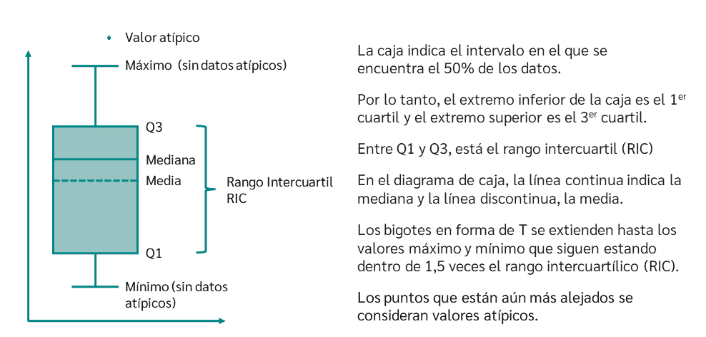

**2. Aplicar técnicas estadísticas para detectar anormalidades**

Una vez observada la posible presencia de valores extremos, es importante respaldar esa observación con métodos estadísticos, como el uso del rango intercuartílico (IQR), desviaciones estándar o puntuaciones z, que permiten cuantificar qué tan alejados están ciertos valores respecto a la media o la mediana.


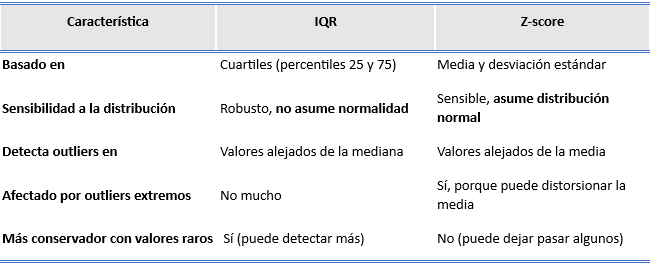




**3. Tomar decisiones sobre los valores atípicos**

Según el contexto del análisis, los valores identificados como atípicos pueden ser eliminados, transformados o conservados. Esta etapa debe considerar si los outliers son errores, casos válidos raros o puntos con significado especial que no deben descartarse.

**Ejemplo. Tratamiento de valores atípicos**

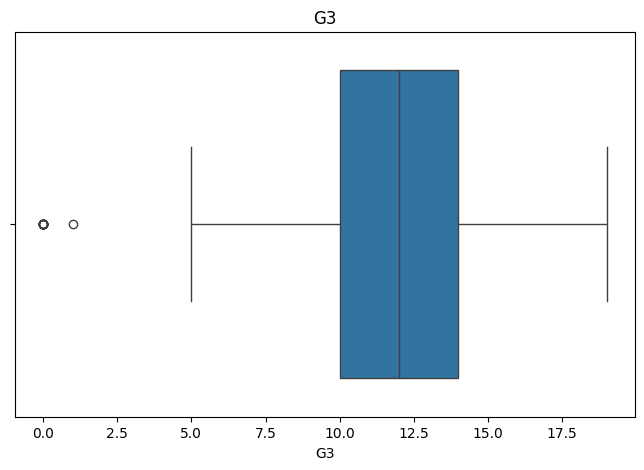

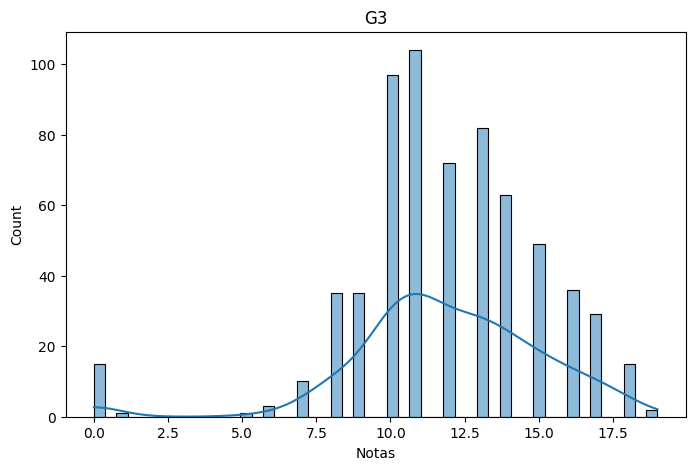

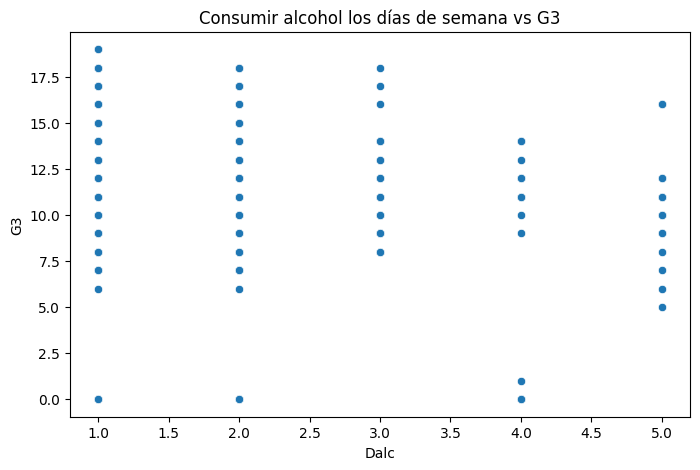

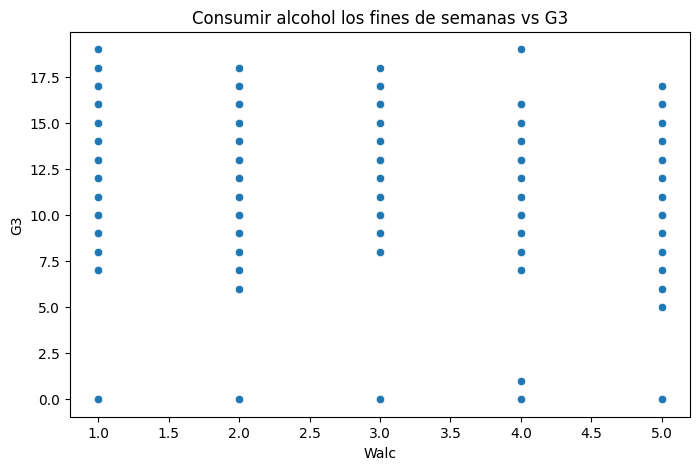

Número de outliers según IQR: 16
Número de outliers según Z-score: 16
Total de registros después de eliminar outliers: 633


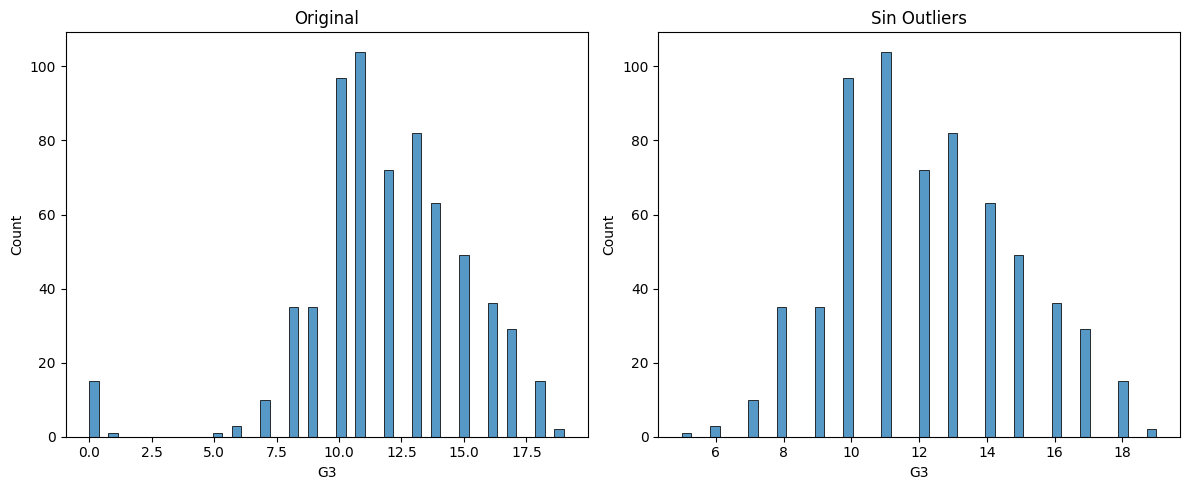

In [25]:
import pandas as pd

# Cargar dataset
df = pd.read_csv("StudentsAlcoholConsumption.csv")


#Paso 1: Exploración visual (detectar outliers visualmente)
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot del monto de tarifa
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['G3'])
plt.title("G3")
plt.show()

# Histograma del monto de tarifa
plt.figure(figsize=(8, 5))
sns.histplot(df['G3'], bins=50, kde=True)
plt.title("G3")
plt.xlabel("Notas")
plt.show()

# Diagrama de dispersión: Dalc vs G3
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Dalc", y='G3', data=df)
plt.title("Consumir alcohol los días de semana vs G3")
plt.show()

# Diagrama de dispersión: Walc vs G3
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Walc", y='G3', data=df)
plt.title("Consumir alcohol los fines de semanas vs G3")
plt.show()

#Paso 2: Detección estadística
#2.1. Con el rango intercuartílico (IQR)
# Calcular Q1, Q3 e IQR
Q1 = df['G3'].quantile(0.25)
Q3 = df['G3'].quantile(0.75)
IQR = Q3 - Q1

# Limites para detectar outliers
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar outliers
outliers_iqr = df[(df['G3'] < limite_inferior) | (df['G3'] > limite_superior)]

print(f"Número de outliers según IQR: {outliers_iqr.shape[0]}")

#B. Con z-score
from scipy import stats
import numpy as np

# Eliminar nulos para aplicar z-score
df_limpio = df[['G3']].dropna()
df_limpio['zscore'] = stats.zscore(df_limpio['G3'])

# Umbral típico z > 3 o z < -3
outliers_z = df_limpio[(df_limpio['zscore'] > 3) | (df_limpio['zscore'] < -3)]

print(f"Número de outliers según Z-score: {outliers_z.shape[0]}")

#Paso 3: Tomar decisiones
# Eliminar outliers usando IQR (como ejemplo)
df_sin_outliers = df[(df['G3'] >= limite_inferior) & (df['G3'] <= limite_superior)]
print(f"Total de registros después de eliminar outliers: {df_sin_outliers.shape[0]}")

# Comparación antes y después (histograma)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['G3'], bins=50)
plt.title("Original")

plt.subplot(1, 2, 2)
sns.histplot(df_sin_outliers['G3'], bins=50)
plt.title("Sin Outliers")
plt.tight_layout()
plt.show()

Identificado los Outliers, realizaremos un análisis exploratorio una correlación estadística y modelos predictivos.

Análisis exploratorio:

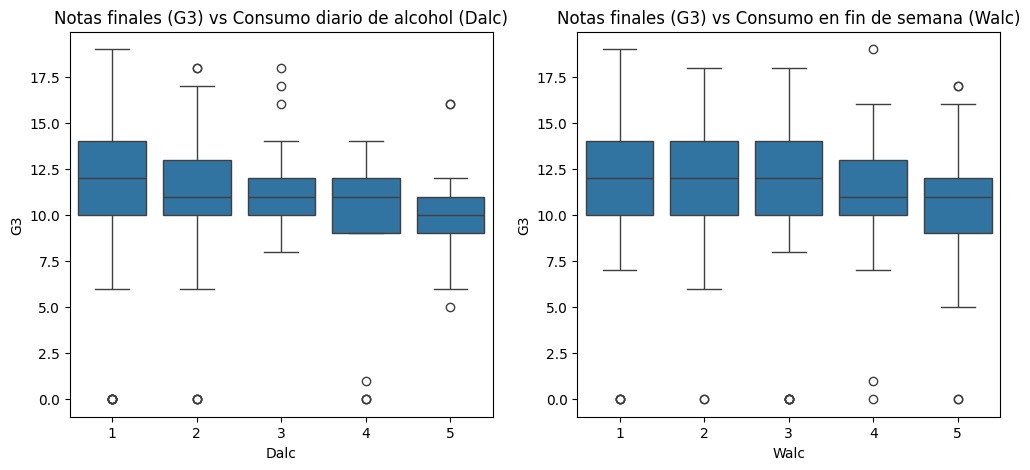

In [12]:
df_no_outliers = df[(df['G3'] >= 5) & (df['G3'] <= 18)]

# Boxplot de G3 por Dalc y Walc
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(x="Dalc", y="G3", data=df)
plt.title("Notas finales (G3) vs Consumo diario de alcohol (Dalc)")

plt.subplot(1,2,2)
sns.boxplot(x="Walc", y="G3", data=df)
plt.title("Notas finales (G3) vs Consumo en fin de semana (Walc)")

plt.show()

Correlación estadística

In [24]:
print(df[['Dalc','Walc','G3']].corr())

          Dalc      Walc        G3
Dalc  1.000000  0.616561 -0.204719
Walc  0.616561  1.000000 -0.176619
G3   -0.204719 -0.176619  1.000000


Modelo predictivo

In [23]:
import statsmodels.api as sm

X = df[['Dalc','Walc']]
y = df['G3']

X = sm.add_constant(X)  # agregar intercepto
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                  0.043
Method:                 Least Squares   F-statistic:                     15.58
Date:                Mon, 25 Aug 2025   Prob (F-statistic):           2.47e-07
Time:                        19:38:32   Log-Likelihood:                -1666.2
No. Observations:                 649   AIC:                             3338.
Df Residuals:                     646   BIC:                             3352.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.1837      0.266     49.493      0.0